# KAN-19 — Variáveis aleatórias e distribuições: fichamento teórico aplicado ao Spaceship Titanic

**Responsável:** Luciana · **Revisora dedicada:** Daniela · **Status:** em revisão (validação de Daniela pendente)

## Mensagens-chave

1. **`Transported` é uma variável de Bernoulli com $p \approx 50{,}4\%$.** As duas classes estão equilibradas. Por isso, a proporção é a medida natural de comparação entre grupos (teste de proporções ou qui-quadrado), e um modelo preditivo precisa superar ~50% de acerto para ter valor.
2. **A idade se aproxima de uma Normal, mas só de forma grosseira.** Ela tem leve assimetria à direita (0,43) e é mais concentrada entre 20 e 40 anos do que a Normal prevê (55,3% contra 51,2%). Comparações de **médias** de idade são seguras pelo Teorema do Limite Central; afirmações sobre **indivíduos** exigem cautela.
3. **Os gastos não seguem um modelo único.** **41,9%** dos passageiros não gastam nada, e entre os que gastam os valores são muito assimétricos. Os gastos positivos lembram uma Log-Normal, mas misturam perfis bem diferentes por planeta de origem (mediana de 826 u.m. na Terra, 5.100 em Europa). A análise deve ser feita em duas perguntas: *o passageiro gastou?* e *quanto gastou, quando gastou?*
4. **Poisson e Exponencial não se aplicam a nenhuma variável do navio.** `GroupSize` é uma contagem, mas nunca vale zero e tem variância maior que a média; não há tempos de espera registrados. As duas ficam como referência teórica.

## Escopo

O card pede a revisão de $P(X=x)$ e $f(x)$, o estudo de cinco modelos e o registro de média, variância e assimetria para interpretar as distribuições reais do navio. Este notebook faz isso e compara cada variável com seu modelo candidato. QQ-plots e testes formais de aderência (Shapiro, K-S) ficam para **KAN-20 e KAN-21**; a escolha dos testes inferenciais, para **KAN-22**.

**Execução:** rode as células em ordem. O notebook procura `data/processed/spaceship_titanic_clean.csv` nas pastas superiores; no Colab, baixa o mesmo arquivo do GitHub (versão fixa da KAN-12). Nenhum arquivo de dados é alterado.

In [1]:
# Configuração: bibliotecas, leitura da base tratada (KAN-12) e formatação dos resultados
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

caminho_relativo = Path("data/processed/spaceship_titanic_clean.csv")
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / caminho_relativo).is_file()), None)
fonte = raiz / caminho_relativo if raiz else (
    "https://raw.githubusercontent.com/gmenezesg/spaceship-titanic-estatistica-posdl/"
    "e58304d9b232f60370b1153843ee8f568e0877b7/data/processed/spaceship_titanic_clean.csv")
df_kan19 = pd.read_csv(fonte)

DESPESAS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
assert not df_kan19[["Transported", "Age", "GroupSize", "TotalSpend", *DESPESAS]].isna().any().any()

# Formatação no padrão brasileiro (vírgula decimal, ponto de milhar)
def br(x, casas=2):
    return f"{x:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def pct(x, casas=1):
    return br(100 * x, casas) + "%"

# Estilo dos gráficos: dados em azul, modelo teórico em laranja, eixos discretos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
    "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})
print(f"Base tratada: {br(len(df_kan19), 0)} passageiros × {df_kan19.shape[1]} colunas")

Base tratada: 8.693 passageiros × 22 colunas


## 1. Fundamentos (Handout Aula 1)

Uma **variável aleatória** associa um número a cada resultado de um experimento aleatório. Aqui, o experimento é sortear ao acaso um passageiro da base e observar uma característica dele.

| | Variável **discreta** | Variável **contínua** |
|---|---|---|
| Valores possíveis | Finitos ou enumeráveis (0, 1, 2, …) | Qualquer valor em um intervalo |
| Descrita por | Função de probabilidade $p_X(x) = P(X=x)$ | Função densidade $f_X(x)$ |
| Condições | $p_X(x) \ge 0$ e $\sum_x p_X(x) = 1$ | $f_X(x) \ge 0$ e $\int_{-\infty}^{\infty} f_X(x)\,dx = 1$ |
| Probabilidade de um intervalo | Soma: $P(a \le X \le b) = \sum_{a \le x \le b} p_X(x)$ | Área: $P(a \le X \le b) = \int_a^b f_X(x)\,dx$ |
| Probabilidade de um ponto | Pode ser positiva | Sempre $P(X = x) = 0$; a altura $f_X(x)$ **não** é probabilidade e pode passar de 1 |
| Exemplos no navio | `Transported` (0/1), `GroupSize` (1 a 8), `Age` (anos inteiros) | Gastos (`RoomService`, …, `TotalSpend`), tratados como contínuos |

**As três propriedades registradas para cada modelo:**

$$\mu = E(X) \qquad \sigma^2 = \operatorname{Var}(X) = E[(X-\mu)^2] \qquad \gamma_1 = \frac{E[(X-\mu)^3]}{\sigma^3}$$

- **Média ($\mu$):** centro de gravidade da distribuição.
- **Variância ($\sigma^2$):** dispersão em torno da média; o desvio-padrão $\sigma$ está na mesma unidade dos dados.
- **Assimetria ($\gamma_1$):** $\gamma_1 > 0$ indica cauda longa à direita (média > mediana); $\gamma_1 < 0$, à esquerda; $\gamma_1 = 0$ é necessário, mas não suficiente, para simetria.

Os parâmetros teóricos ($\mu$, $\sigma^2$, $\gamma_1$) descrevem o modelo; as medidas calculadas na base ($\bar{x}$, $s^2$, assimetria amostral) são **estimativas**. A comparação entre as duas é o que permite dizer se um modelo é razoável.

## 2. Os cinco modelos teóricos

### 2.1. Quadro-resumo

| Modelo | Tipo | Função | Média | Variância | Assimetria $\gamma_1$ | Situação típica |
|---|---|---|---|---|---|---|
| **Binomial** $(n, p)$ | Discreta, $k = 0, \ldots, n$ | $\binom{n}{k}p^k(1-p)^{n-k}$ | $np$ | $np(1-p)$ | $\dfrac{1-2p}{\sqrt{np(1-p)}}$ | Nº de sucessos em $n$ ensaios independentes com mesma chance $p$ |
| **Poisson** $(\lambda)$ | Discreta, $k = 0, 1, 2, \ldots$ | $\dfrac{e^{-\lambda}\lambda^k}{k!}$ | $\lambda$ | $\lambda$ | $\dfrac{1}{\sqrt{\lambda}}$ | Nº de eventos raros em um intervalo de tempo ou espaço |
| **Normal** $(\mu, \sigma^2)$ | Contínua, $x \in \mathbb{R}$ | $\dfrac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$ | $\mu$ | $\sigma^2$ | $0$ | Soma de muitos efeitos pequenos; médias amostrais (TLC) |
| **Log-Normal** $(\mu, \sigma^2)$ | Contínua, $x > 0$ | $\dfrac{1}{x\sigma\sqrt{2\pi}}e^{-\frac{(\ln x-\mu)^2}{2\sigma^2}}$ | $e^{\mu+\sigma^2/2}$ | $(e^{\sigma^2}-1)e^{2\mu+\sigma^2}$ | $(e^{\sigma^2}+2)\sqrt{e^{\sigma^2}-1}$ | Valores positivos que crescem de forma multiplicativa (renda, gastos) |
| **Exponencial** $(\lambda)$ | Contínua, $x \ge 0$ | $\lambda e^{-\lambda x}$ | $1/\lambda$ | $1/\lambda^2$ | $2$ | Tempo de espera até o próximo evento de um processo de Poisson |

**Notas de leitura**

- **Bernoulli** é a Binomial com $n = 1$: média $p$, variância $p(1-p)$.
- **Binomial** é simétrica se $p = 0{,}5$; com $p < 0{,}5$ tem cauda à direita. Em sorteios **sem** reposição de uma população finita, a distribuição exata é a Hipergeométrica.
- **Poisson** tem média igual à variância. Se nos dados a variância for bem maior que a média (*superdispersão*), o modelo não serve.
- **Normal:** cerca de 68,3% dos valores ficam em $\mu \pm \sigma$ e 95,4% em $\mu \pm 2\sigma$; média = mediana = moda.
- **Log-Normal:** $X$ é Log-Normal quando $\ln X$ é Normal; $\mu$ e $\sigma$ são os parâmetros **do logaritmo**. Mediana $= e^{\mu} <$ média. Não admite zeros.
- **Exponencial:** tem *falta de memória*, $P(X > s+t \mid X > s) = P(X > t)$. Na Poisson, $\lambda$ é contagem esperada no intervalo; na Exponencial, é taxa por unidade de tempo. Também não gera zeros exatos: $P(X = 0) = 0$.

### 2.2. O formato de cada modelo

O painel mostra como cada modelo distribui a probabilidade e quanto ele é assimétrico. Os parâmetros são apenas ilustrativos e servem de referência visual para os histogramas reais da seção 3.

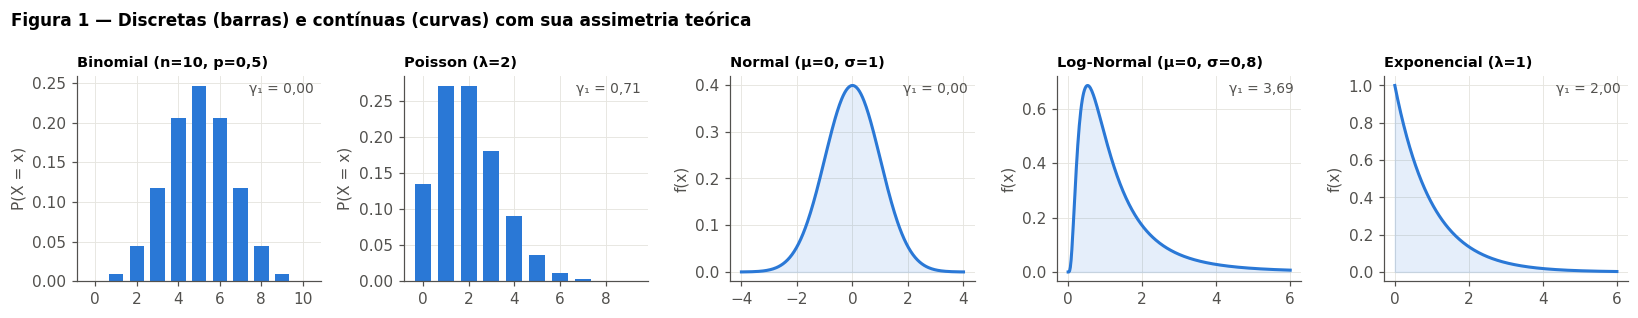

In [2]:
# Painel com a forma de cada modelo e sua assimetria teórica
fig, eixos = plt.subplots(1, 5, figsize=(15, 2.9))
modelos = [
    ("Binomial (n=10, p=0,5)", stats.binom(10, 0.5), np.arange(11), True),
    ("Poisson (λ=2)", stats.poisson(2), np.arange(10), True),
    ("Normal (μ=0, σ=1)", stats.norm(), np.linspace(-4, 4, 300), False),
    ("Log-Normal (μ=0, σ=0,8)", stats.lognorm(0.8), np.linspace(0.001, 6, 300), False),
    ("Exponencial (λ=1)", stats.expon(), np.linspace(0, 6, 300), False),
]
for ax, (nome, dist, x, discreta) in zip(eixos, modelos):
    if discreta:
        ax.bar(x, dist.pmf(x), color=AZUL, width=0.7)
        ax.set_xticks(x[::2])
        ax.set_ylabel("P(X = x)")
    else:
        ax.plot(x, dist.pdf(x), color=AZUL, lw=2)
        ax.fill_between(x, dist.pdf(x), color=AZUL, alpha=0.12)
        ax.set_ylabel("f(x)")
    ax.set_title(nome, fontsize=9.5)
    ax.text(0.97, 0.92, f"γ₁ = {br(float(dist.stats(moments='s')))}", transform=ax.transAxes,
            ha="right", fontsize=9, color=CINZA)
fig.suptitle("Figura 1 — Discretas (barras) e contínuas (curvas) com sua assimetria teórica",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

**Leitura da Figura 1.** Binomial com $p = 0{,}5$ e Normal são simétricas ($\gamma_1 = 0$). Poisson, Log-Normal e Exponencial têm cauda à direita. A da Exponencial é fixa ($\gamma_1 = 2$); a da Log-Normal cresce rapidamente com $\sigma$. Na seção 3, comparamos a assimetria observada em cada variável do navio com esses valores para descartar ou manter um modelo.

## 3. Dados reais do navio × modelos teóricos

### 3.1. Visão geral

A tabela reúne média, mediana, desvio-padrão, assimetria e proporção de zeros das variáveis quantitativas, ao lado do modelo de referência indicado pela teoria.

In [3]:
# Momentos empíricos de cada variável e o modelo de referência sugerido pela teoria
referencia = {
    "Age": "Normal (aproximação)",
    "GroupSize": "Nenhum dos cinco (não é Poisson)",
    **{c: "Zeros + Log-Normal nos positivos" for c in DESPESAS},
    "TotalSpend": "Zeros + Log-Normal nos positivos",
}
linhas = []
for col, modelo in referencia.items():
    x = df_kan19[col]
    linhas.append({
        "Variável": col,
        "Média": br(x.mean()),
        "Mediana": br(x.median()),
        "Desvio-padrão": br(x.std()),
        "Assimetria": br(x.skew()),
        "% de zeros": pct((x == 0).mean()),
        "Modelo de referência": modelo,
    })
display(pd.DataFrame(linhas).set_index("Variável"))

,Média,Mediana,Desvio-padrão,Assimetria,% de zeros,Modelo de referência
Variável,,,,,,
Age,"28,78","27,00","14,35","0,43","2,0%",Normal (aproximação)
GroupSize,"2,04","1,00","1,60","1,89","0,0%",Nenhum dos cinco (não é Poisson)
RoomService,"221,58","0,00","660,80","6,38","65,2%",Zeros + Log-Normal nos positivos
FoodCourt,"451,40","0,00","1.596,28","7,17","63,8%",Zeros + Log-Normal nos positivos
ShoppingMall,"169,95","0,00","597,95","12,77","65,8%",Zeros + Log-Normal nos positivos
Spa,"305,45","0,00","1.125,46","7,72","62,3%",Zeros + Log-Normal nos positivos
VRDeck,"299,09","0,00","1.134,08","7,90","64,4%",Zeros + Log-Normal nos positivos
TotalSpend,"1.447,46","717,00","2.808,28","4,40","41,9%",Zeros + Log-Normal nos positivos


**O que a tabela mostra**

- **Idade** é a única variável quase simétrica (assimetria 0,43; média 28,8 e mediana 27). É a única candidata razoável à Normal.
- **Cada tipo de gasto** tem entre **62% e 66% de zeros** e assimetria entre **6 e 13**, muito acima da Exponencial ($\gamma_1 = 2$). A mediana zero mostra que o passageiro típico não usa a comodidade, enquanto a média é puxada por poucos gastadores altos. Nenhum modelo contínuo isolado descreve essa combinação.
- **`TotalSpend`** reduz os zeros para 41,9%, mas continua muito assimétrico (4,40). A média (1.447) é o dobro da mediana (717).
- **`GroupSize`** é uma contagem com assimetria 1,89. A seção 3.5 mostra por que ela não é Poisson.

Nas seções seguintes, cada variável é examinada contra seu modelo candidato.

### 3.2. `Transported` → Bernoulli e Binomial

Codificando *transportado* = 1 e *não transportado* = 0, a variável é Bernoulli. A proporção observada é a estimativa de $p$.

,Valor
Medida,
Transportados,4.378
Não transportados,4.315
p = P(X = 1),"50,36%"
Média do indicador,"0,5036"
Variância do indicador,"0,2500"
Variância teórica p(1 − p),"0,2500"


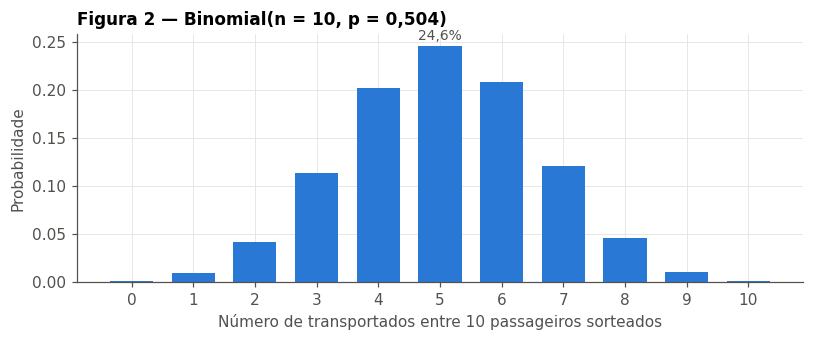

P(exatamente 5) = 24,6% | P(3 a 7) = 89,1% | P(≤ 2 ou ≥ 8) = 10,9%
Média = 5,04 | Variância = 2,50 | Assimetria = -0,005


In [4]:
# Bernoulli: proporção de transportados e conferência de média e variância
y = df_kan19["Transported"].astype(int)
p = y.mean()
display(pd.DataFrame({
    "Medida": ["Transportados", "Não transportados", "p = P(X = 1)", "Média do indicador", "Variância do indicador", "Variância teórica p(1 − p)"],
    "Valor": [br(y.sum(), 0), br((1 - y).sum(), 0), pct(p, 2), br(y.mean(), 4), br(y.var(ddof=0), 4), br(p * (1 - p), 4)],
}).set_index("Medida"))

# Binomial: quantos transportados esperar ao sortear 10 passageiros ao acaso (com reposição)
n = 10
binom = stats.binom(n, p)
k = np.arange(n + 1)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(k, binom.pmf(k), color=AZUL, width=0.7)
for ki in (5,):
    ax.annotate(pct(binom.pmf(ki)), (ki, binom.pmf(ki)), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=9, color=CINZA)
ax.set(xticks=k, xlabel="Número de transportados entre 10 passageiros sorteados", ylabel="Probabilidade",
       title="Figura 2 — Binomial(n = 10, p = 0,504)")
fig.tight_layout()
plt.show()
print(f"P(exatamente 5) = {pct(binom.pmf(5))} | P(3 a 7) = {pct(binom.cdf(7) - binom.cdf(2))} | "
      f"P(≤ 2 ou ≥ 8) = {pct(1 - (binom.cdf(7) - binom.cdf(2)))}")
print(f"Média = {br(binom.mean())} | Variância = {br(binom.var())} | Assimetria = {br(float(binom.stats(moments='s')), 3)}")

**Interpretação.**

- **Classes equilibradas:** 4.378 de 8.693 passageiros (**50,36%**) foram transportados. A média do indicador é exatamente essa proporção, e a variância é $p(1-p) \approx 0{,}25$, o valor máximo possível para uma Bernoulli.
- **Consequência para o projeto:** como as classes têm o mesmo tamanho, a acurácia de um modelo preditivo é uma métrica honesta, e o patamar a superar é cerca de 50%.
- **Variação esperada pelo acaso:** em 10 passageiros sorteados ao acaso, o resultado mais provável é 5 transportados (24,6%). Ainda assim, há **89%** de chance de observar entre 3 e 7, e **11%** de cair fora disso. Diferenças de proporção em grupos pequenos (por exemplo, uma família de 4) podem ser puro acaso, o que justifica testes formais na KAN-22.
- **Pressuposto:** a Binomial exige ensaios independentes. Passageiros de um mesmo grupo de viagem tendem a ter o mesmo desfecho, então contagens **dentro de grupos reais** não são Binomiais.

### 3.3. `Age` → Normal

Ajustamos uma Normal com a média e o desvio-padrão da idade e comparamos a curva com o histograma.

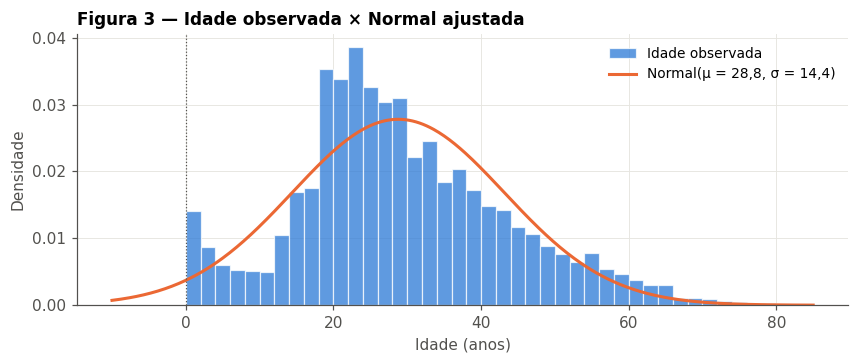

,Observado na base,Previsto pela Normal
Faixa,,
"Média ± 1 desvio (14,4 a 43,1 anos)","71,9%","68,3%"
20 a 40 anos,"55,3%","51,2%"
Menos de 0 ano,"0,0%","2,2%"
60 anos ou mais,"2,9%","1,5%"


Assimetria observada = 0,43 (Normal: 0) | Média = 28,78 | Mediana = 27,00


In [5]:
# Normal ajustada à idade: comparação visual e de probabilidades
idade = df_kan19["Age"]
normal = stats.norm(idade.mean(), idade.std())

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(idade, bins=np.arange(0, 82, 2), density=True, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.8,
        label="Idade observada")
grade = np.linspace(-10, 85, 400)
ax.plot(grade, normal.pdf(grade), color=LARANJA, lw=2, label=f"Normal(μ = {br(idade.mean(), 1)}, σ = {br(idade.std(), 1)})")
ax.axvline(0, color=CINZA, lw=0.8, ls=":")
ax.set(xlabel="Idade (anos)", ylabel="Densidade", title="Figura 3 — Idade observada × Normal ajustada")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Faixa": ["Média ± 1 desvio (14,4 a 43,1 anos)", "20 a 40 anos", "Menos de 0 ano", "60 anos ou mais"],
    "Observado na base": [pct(idade.between(normal.mean() - normal.std(), normal.mean() + normal.std()).mean()),
                          pct(idade.between(20, 40).mean()), pct(0), pct((idade >= 60).mean())],
    "Previsto pela Normal": [pct(normal.cdf(normal.mean() + normal.std()) - normal.cdf(normal.mean() - normal.std())),
                             pct(normal.cdf(40) - normal.cdf(20)), pct(normal.cdf(0)), pct(normal.sf(60))],
}).set_index("Faixa"))
print(f"Assimetria observada = {br(idade.skew())} (Normal: 0) | Média = {br(idade.mean())} | Mediana = {br(idade.median())}")

**Interpretação.**

- **Mais concentrada que a Normal:** **71,9%** dos passageiros estão a até 1 desvio-padrão da média, contra 68,3% numa Normal.
- **Formato:** a idade tem formato de sino, mas não é Normal. O pico entre 18 e 30 anos é mais alto que o da curva, a cauda direita é mais longa (assimetria 0,43, média 28,8 > mediana 27), e há um grupo de crianças pequenas que a Normal não captura.
- **Onde a Normal erra:** ela subestima a concentração em adultos jovens (prevê 51,2% entre 20 e 40 anos, a base tem 55,3%) e atribui **2,2%** de probabilidade a idades negativas, que são impossíveis.
- **Consequência para o projeto:**
  - **Médias de idade:** comparar idade média entre transportados e não transportados é seguro com $n \approx 8.700$, porque pelo TLC a **média amostral** é aproximadamente Normal mesmo que a idade individual não seja.
  - **Testes de normalidade:** um teste formal tende a rejeitar a normalidade da idade com uma amostra desse tamanho. Isso será verificado com QQ-plot na KAN-21 e não invalida o uso da média.
- **Ressalvas:** a idade está registrada em anos inteiros, e 2% dos valores foram imputados na KAN-11, o que concentra observações na mediana.

### 3.4. Gastos → zeros + Log-Normal nos valores positivos

Os gastos têm duas partes: uma massa de passageiros com gasto exatamente zero e uma distribuição contínua entre quem gasta. A teoria da seção 2 mostra que Log-Normal e Exponencial não produzem zeros exatos, então as duas partes precisam ser analisadas separadamente.

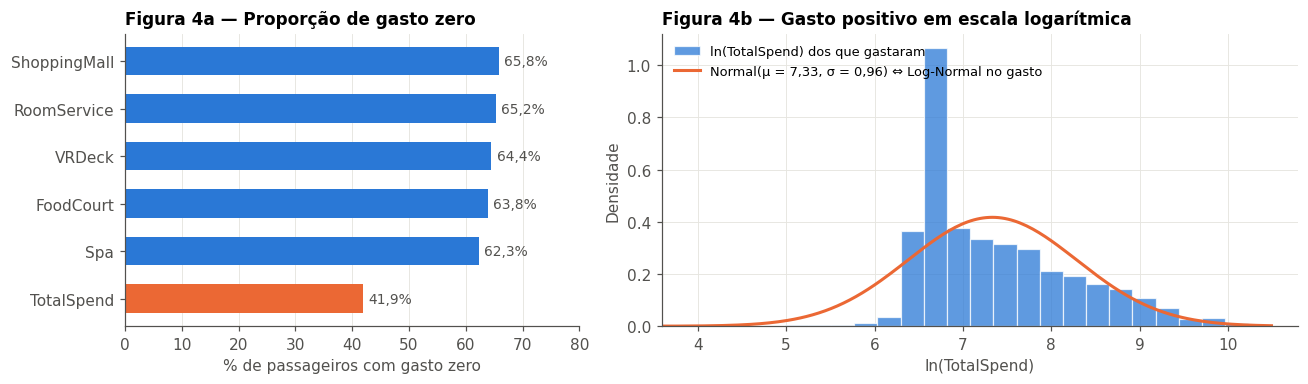

,Observado,Previsto pela Log-Normal
Medida (passageiros com gasto > 0),,
Quantidade,5.049,—
Média,"2.492,13","2.417,20"
Mediana,"1.192,00","1.529,53"
Desvio-padrão,"3.312,59","2.958,02"
Assimetria,"3,70","5,50"


Assimetria de ln(gasto positivo) = -0,35 (uma Log-Normal perfeita teria 0)
Gastadores entre 735 e 945 u.m.: 25,2%; destes, 96,2% são da Terra


,Passageiros,Mediana,Média
HomePlanet,,,
Earth,2.949,826,1.080
Europa,1.128,5.100,6.638
Mars,972,1.590,1.967


In [6]:
# Parte 1: quem gasta. Parte 2: quanto gasta quem gasta (Log-Normal nos positivos)
positivos = df_kan19.loc[df_kan19["TotalSpend"] > 0, "TotalSpend"]
log_pos = np.log(positivos)
mu, sigma = log_pos.mean(), log_pos.std(ddof=0)          # estimadores de máxima verossimilhança
lognormal = stats.lognorm(s=sigma, scale=np.exp(mu))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
zeros = (df_kan19[DESPESAS + ["TotalSpend"]] == 0).mean().sort_values()
ax1.barh(zeros.index, zeros.values * 100, color=[LARANJA if c == "TotalSpend" else AZUL for c in zeros.index], height=0.6)
for i, v in enumerate(zeros.values):
    ax1.text(v * 100 + 1, i, pct(v), va="center", fontsize=9, color=CINZA)
ax1.set(xlim=(0, 80), xlabel="% de passageiros com gasto zero", title="Figura 4a — Proporção de gasto zero")
ax1.grid(axis="y", visible=False)

ax2.hist(log_pos, bins=40, density=True, color=AZUL, alpha=0.75, edgecolor="white", linewidth=0.8,
         label="ln(TotalSpend) dos que gastaram")
grade = np.linspace(log_pos.min(), log_pos.max(), 300)
ax2.plot(grade, stats.norm(mu, sigma).pdf(grade), color=LARANJA, lw=2,
         label=f"Normal(μ = {br(mu)}, σ = {br(sigma)}) ⇔ Log-Normal no gasto")
ax2.set(xlim=(np.percentile(log_pos, 0.5) - 0.5, log_pos.max() + 0.3),  # oculta poucos gastos de 1 a 50 u.m.
        xlabel="ln(TotalSpend)", ylabel="Densidade", title="Figura 4b — Gasto positivo em escala logarítmica")
ax2.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()

display(pd.DataFrame({
    "Medida (passageiros com gasto > 0)": ["Quantidade", "Média", "Mediana", "Desvio-padrão", "Assimetria"],
    "Observado": [br(len(positivos), 0), br(positivos.mean()), br(positivos.median()), br(positivos.std(ddof=0)), br(stats.skew(positivos))],
    "Previsto pela Log-Normal": ["—", br(lognormal.mean()), br(lognormal.median()), br(lognormal.std()), br(float(lognormal.stats(moments="s")))],
}).set_index("Medida (passageiros com gasto > 0)"))
print(f"Assimetria de ln(gasto positivo) = {br(stats.skew(log_pos))} (uma Log-Normal perfeita teria 0)")

# O pico em ln ≈ 6,7 (735 a 945 u.m.): de onde vêm esses passageiros?
gastadores = df_kan19[df_kan19["TotalSpend"] > 0]
no_pico = gastadores["TotalSpend"].between(735, 945)
print(f"Gastadores entre 735 e 945 u.m.: {pct(no_pico.mean())}; destes, {pct((gastadores.loc[no_pico, 'HomePlanet'] == 'Earth').mean())} são da Terra")
display(gastadores.groupby("HomePlanet")["TotalSpend"].agg(
    Passageiros=lambda s: br(len(s), 0), Mediana=lambda s: br(s.median(), 0), Média=lambda s: br(s.mean(), 0)))

**Interpretação.**

- **Parte 1, quem gasta:**
  - **Por comodidade:** cerca de 2 em cada 3 passageiros não usam cada comodidade (62% a 66% de zeros).
  - **No total:** 41,9% não gastam nada. A KAN-11 mostra a causa: passageiros em criossono e crianças de até 12 anos têm gasto zero por regra.
  - **Como tratar:** essa parte é uma variável **Bernoulli** (`HasSpent`), e sua relação com `Transported` deve ser analisada como proporção ou qui-quadrado.
- **Parte 2, quanto gasta quem gasta:**
  - **No logaritmo:** o histograma tem formato de sino, centrado em $e^{7{,}33} \approx 1.530$ unidades monetárias, que é a mediana prevista pela Log-Normal (a observada é 1.192). A Log-Normal é, portanto, um **modelo de trabalho razoável** para os gastos positivos.
  - **Uma mistura de populações:** a Figura 4b tem um pico estreito em torno de 800 u.m. que a curva não acompanha. **25%** dos gastadores estão entre 735 e 945 u.m., e **96%** deles vêm da **Terra**. A mediana de gasto é 826 u.m. para terráqueos, 1.590 para marcianos e 5.100 para europeus. Os gastos positivos são, na verdade, **três distribuições sobrepostas**, uma por planeta de origem, e uma única Log-Normal resume esse conjunto apenas de forma aproximada.
  - **Na cauda:** o ajuste também não é perfeito. Em escala log há leve assimetria à esquerda (−0,35), e a assimetria real dos gastos (3,70) é menor que a prevista (5,50). Os gastos muito altos são **menos extremos** do que a Log-Normal sugere.
- **Consequência para o projeto:**
  - **Testes:** comparar médias de gasto bruto com teste t é frágil, porque a média é dominada pela cauda. É preferível comparar em escala $\ln(1+X)$, usar a mediana ou um teste não paramétrico (Mann-Whitney). A escolha final é da KAN-22.
  - **Regressão:** gastos em escala log tendem a produzir resíduos mais bem comportados, e `HomePlanet` deve entrar como variável explicativa.
  - **Comparações justas:** comparar gastos entre grupos sem controlar o planeta de origem pode confundir o efeito do planeta com o do grupo.

### 3.5. `GroupSize` → por que não é Poisson (e por que a Exponencial também não se aplica)

`GroupSize` é uma contagem, o que poderia sugerir Poisson. A teoria dá dois critérios objetivos para verificar: a Poisson admite o valor 0, e tem média igual à variância.

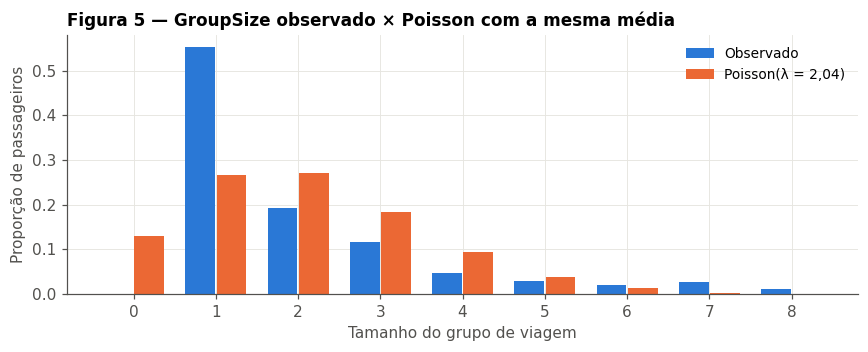

Média = 2,04 | Variância = 2,55 (Poisson exigiria variância = média)
Grupos de tamanho 0: observado 0,0% × Poisson 13,1%
Viajam sozinhos (tamanho 1): observado 55,3% × Poisson 26,6%


In [7]:
# Distribuição observada de GroupSize contra uma Poisson com a mesma média
g = df_kan19["GroupSize"]
poisson = stats.poisson(g.mean())
k = np.arange(0, 9)
obs = g.value_counts(normalize=True).reindex(k, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(k - 0.19, obs.values, width=0.36, color=AZUL, label="Observado")
ax.bar(k + 0.19, poisson.pmf(k), width=0.36, color=LARANJA, label=f"Poisson(λ = {br(g.mean())})")
ax.set(xticks=k, xlabel="Tamanho do grupo de viagem", ylabel="Proporção de passageiros",
       title="Figura 5 — GroupSize observado × Poisson com a mesma média")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
print(f"Média = {br(g.mean())} | Variância = {br(g.var())} (Poisson exigiria variância = média)")
print(f"Grupos de tamanho 0: observado {pct(0)} × Poisson {pct(poisson.pmf(0))}")
print(f"Viajam sozinhos (tamanho 1): observado {pct(obs[1])} × Poisson {pct(poisson.pmf(1))}")

**Interpretação.**

- **Por que não é Poisson:** os dois critérios falham.
  - Um grupo de viagem tem **no mínimo 1** pessoa, mas a Poisson atribui **13,1%** de probabilidade ao tamanho 0.
  - A **variância (2,55) é maior que a média (2,04)**, ou seja, há superdispersão.
  - O padrão real também é diferente: **55%** viajam sozinhos (a Poisson prevê 26,6%), e há mais grupos grandes do que o modelo prevê. Isso decorre do processo que forma os grupos (famílias, amigos), não de eventos independentes a uma taxa constante.
- **Consequência para o projeto:** `GroupSize` deve ser tratada como **ordinal ou categórica** (sozinho × grupo, ou faixas de tamanho) em testes qui-quadrado, e não modelada como contagem Poisson.
- **Exponencial:** não há nenhuma variável de tempo de espera ou duração na base, então ela não tem aplicação aqui. Ser positiva e assimétrica não basta: os gastos têm assimetria entre 4 e 13, muito acima da assimetria fixa de 2 da Exponencial, e têm massa em zero, que ela não produz.

## 4. Implicações para as próximas etapas (KAN-20 a KAN-22)

| Variável | Modelo de referência | Evidência desta etapa | Consequência para a análise |
|---|---|---|---|
| `Transported` | Bernoulli ($p = 0{,}504$) | Variância = $p(1-p)$; classes equilibradas | Comparar **proporções** entre grupos (qui-quadrado, teste de proporções); acurácia é métrica válida |
| `Age` | Normal (aproximação) | Assimetria 0,43; 2,2% de massa em idades negativas | **Teste t** para médias é seguro pelo TLC; confirmar o formato com QQ-plot (KAN-21) |
| Gastos e `TotalSpend` | Bernoulli (gastou?) + Log-Normal (quanto?) | 41,9% de zeros; ln(gasto) quase simétrico | Separar `HasSpent` (qui-quadrado) do valor; usar $\ln(1+X)$, mediana ou **Mann-Whitney** |
| `GroupSize` | Nenhum dos cinco | Sem zeros; variância > média | Tratar como **categórica/ordinal** |

### Ligação com a Aula 3: distribuição dos dados × distribuição da média

O **Teorema do Limite Central** afirma que, para observações independentes com variância finita, a **média amostral** $\bar{X}$ tem distribuição aproximadamente Normal para $n$ grande, com média $\mu$ e erro-padrão $\sigma/\sqrt{n}$ (estimado por $s/\sqrt{n}$). Isso explica por que um teste de médias pode ser usado com a idade mesmo sem os dados individuais serem Normais. Para os gastos, a cauda pesada exige amostras bem maiores para a aproximação ser boa, e a média continua sendo pouco representativa do passageiro típico.

**Diferença essencial:** o **desvio-padrão** mede a variação entre passageiros; o **erro-padrão** mede a precisão da média estimada.

### Limitações

- **Imputação:** os momentos foram calculados na base tratada da KAN-12, que inclui ~2% de valores imputados por variável, o que tende a reduzir a variância.
- **Dependência entre passageiros:** passageiros do mesmo grupo não são independentes, um pressuposto da Binomial e do TLC.
- **Ajustes ainda informais:** as comparações desta etapa são descritivas. A confirmação formal (QQ-plot, Shapiro-Wilk, Kolmogorov-Smirnov) fica para a KAN-21.

## 5. Síntese Metodológica do Fichamento (`KAN-19`)

1. **Fundamentos registrados:** função de probabilidade $P(X=x)$ para variáveis discretas e função densidade $f(x)$ para contínuas, com as propriedades de **média, variância e assimetria** dos cinco modelos (Binomial, Poisson, Normal, Log-Normal e Exponencial) consolidadas no quadro da seção 2.1.
2. **`Transported` é Bernoulli** com $p = $ **50,36%** (4.378 de 8.693). As classes equilibradas tornam a proporção a medida central de comparação e fixam em ~50% o patamar mínimo para um modelo preditivo.
3. **`Age` é aproximadamente Normal só no formato geral:** assimetria **0,43**, **55,3%** entre 20 e 40 anos contra **51,2%** previstos, e **2,2%** de probabilidade atribuída a idades negativas. Testes de médias são válidos pelo TLC.
4. **Gastos combinam massa em zero e cauda longa:** **41,9%** com `TotalSpend` = 0 (62% a 66% por comodidade) e assimetria de **4,4 a 12,8**. Entre os positivos, a **Log-Normal** ($\mu = 7{,}33$, $\sigma = 0{,}96$ no log) é um modelo de trabalho adequado, com cauda real mais leve que a prevista (assimetria **3,70** contra **5,50**). O desvio vem de uma mistura por planeta de origem: **96%** do pico em torno de 800 u.m. são terráqueos (mediana **826**, contra **5.100** em Europa).
5. **Poisson e Exponencial não se aplicam:** `GroupSize` não tem zeros e é superdispersa (variância **2,55** > média **2,04**); não existem tempos de espera na base.
6. **Recomendação para a KAN-22:** proporções e qui-quadrado para desfechos binários, teste t para a idade, e escala log ou métodos não paramétricos para gastos.

## 6. Referências

- **Handouts Aula 1 — Distribuições de Probabilidade**, Prof. Adiel Filho: variáveis aleatórias, função de probabilidade e densidade, Bernoulli, Binomial, Poisson, Normal e Exponencial.
- **Handouts Aula 1 — Resumo de Probabilidade (rev. 01)**, Prof. Adiel Filho: espaço amostral, eventos e axiomas.
- **Handouts Aula 3 — Distribuições Amostrais e Estimação**, Prof. Adiel Filho: distribuição amostral, Teorema do Limite Central e erro-padrão.
- **Log-Normal (complemento):** NIST/SEMATECH, *e-Handbook of Statistical Methods*, seção 1.3.6.6.9 — https://www.itl.nist.gov/div898/handbook/eda/section3/eda3669.htm
- **Dados:** `docs/dicionario_dados.md` e `data/processed/spaceship_titanic_clean.csv` (KAN-12) do repositório da equipe.